# Practical 11 — K-Means Clustering

**Aim:** Group unlabelled observations into *k* clusters with K-means, choose *k* (elbow method + silhouette score),
and evaluate the clustering.

**Dataset:** Wine dataset (178 wines, 13 chemical measurements; UCI repository, bundled with scikit-learn).
We **ignore the wine-cultivar labels while clustering** (unsupervised) and use them only afterwards to check how well the
clusters match the real groups.

**Idea – Lloyd's algorithm:**
1. Pick *k* initial centroids.
2. **Assign** every point to its nearest centroid (Euclidean distance).
3. **Update** every centroid to the mean of the points assigned to it.
4. Repeat 2–3 until the assignments no longer change. The objective being minimised is the **inertia** (WCSS) = Σ ‖x − centroid‖².

*Note:* the train/test-split and k-fold-CV protocol of the syllabus applies to supervised models; for clustering we evaluate
with internal indices (inertia, silhouette, Davies–Bouldin), external indices against the known labels (ARI, NMI), and we also
show how a fitted model assigns **unseen** (held-out) points.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans
from sklearn.datasets import load_wine
from sklearn.decomposition import PCA
from sklearn.metrics import (silhouette_score, silhouette_samples, davies_bouldin_score,
                             calinski_harabasz_score, adjusted_rand_score, normalized_mutual_info_score)
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

pd.set_option("display.precision", 4)
np.random.seed(42)

## Step 1 — Load and inspect the data

In [2]:
wine = load_wine(as_frame=True)
df = wine.frame
X_df, y_true = df.drop(columns="target"), df["target"].values
print("Shape:", X_df.shape, "| missing values:", int(X_df.isna().sum().sum()))
print("True cultivar counts (NOT used for clustering):", np.bincount(y_true))
display(X_df.describe().T[["mean", "std", "min", "max"]])

Shape: (178, 13) | missing values: 0
True cultivar counts (NOT used for clustering): [59 71 48]


,mean,std,min,max
alcohol,13.0006,0.8118,11.03,14.83
malic_acid,2.3363,1.1171,0.74,5.80
ash,2.3665,0.2743,1.36,3.23
alcalinity_of_ash,19.4949,3.3396,10.60,30.00
magnesium,99.7416,14.2825,70.00,162.00
total_phenols,2.2951,0.6259,0.98,3.88
flavanoids,2.0293,0.9989,0.34,5.08
nonflavanoid_phenols,0.3619,0.1245,0.13,0.66
proanthocyanins,1.5909,0.5724,0.41,3.58
color_intensity,5.0581,2.3183,1.28,13.00


## Step 2 — Scale the features
K-means uses Euclidean distance, so a feature with a large range (proline ≈ 300–1700) would swamp one with a small range
(hue ≈ 0.5–1.7). Standardising gives every feature equal weight.

In [3]:
X = StandardScaler().fit_transform(X_df)
print("Scaled means ≈ 0:", X.mean(axis=0).round(3)[:5], "...")
print("Scaled stds  = 1:", X.std(axis=0).round(3)[:5], "...")

Scaled means ≈ 0: [ 0.  0. -0. -0. -0.] ...
Scaled stds  = 1: [1. 1. 1. 1. 1.] ...


## Step 3 — Lloyd's algorithm by hand (k = 3)
We choose 3 random data points as the starting centroids and print what happens in every iteration.

In [4]:
def kmeans_manual(X, k, init_centroids, max_iter=100, verbose=True):
    centroids = init_centroids.copy()
    for it in range(1, max_iter + 1):
        # Step A – ASSIGN: distance of every point to every centroid → nearest centroid index
        dists = np.linalg.norm(X[:, None, :] - centroids[None, :, :], axis=2)      # (n_samples, k)
        labels = dists.argmin(axis=1)
        # Step B – UPDATE: each centroid becomes the mean of its assigned points
        new_centroids = np.array([X[labels == c].mean(axis=0) for c in range(k)])
        inertia = np.sum((X - new_centroids[labels]) ** 2)
        shift = np.linalg.norm(new_centroids - centroids)
        if verbose:
            print(f"iter {it:2d} | cluster sizes = {np.bincount(labels, minlength=k)} | inertia = {inertia:9.3f} | centroid shift = {shift:.5f}")
        centroids = new_centroids
        if shift < 1e-8:                                                           # Step C – converged
            if verbose: print("→ centroids stopped moving: converged.")
            break
    return labels, centroids, inertia

rng = np.random.RandomState(0)
init = X[rng.choice(len(X), 3, replace=False)]
print("Initial centroids are data points #", [int(np.where((X == r).all(axis=1))[0][0]) for r in init], "\n")
labels_m, cent_m, inertia_m = kmeans_manual(X, 3, init)

Initial centroids are data points # [54, 151, 63] 

iter  1 | cluster sizes = [68 53 57] | inertia =  1330.031 | centroid shift = 4.33330
iter  2 | cluster sizes = [63 53 62] | inertia =  1281.527 | centroid shift = 0.39052
iter  3 | cluster sizes = [63 51 64] | inertia =  1279.966 | centroid shift = 0.15161
iter  4 | cluster sizes = [63 51 64] | inertia =  1279.966 | centroid shift = 0.00000
→ centroids stopped moving: converged.


## Step 4 — Same start in scikit-learn
Passing the *same* initial centroids (`init=array`, `n_init=1`) must give the same result as our loop.

In [5]:
km_same = KMeans(n_clusters=3, init=init, n_init=1, max_iter=300, tol=1e-12).fit(X)
print("Inertia – manual: %.4f | sklearn: %.4f" % (inertia_m, km_same.inertia_))
print("Same cluster assignments:", np.array_equal(labels_m, km_same.labels_))
print("Same centroids:", np.allclose(np.sort(cent_m, axis=0), np.sort(km_same.cluster_centers_, axis=0), atol=1e-4))

Inertia – manual: 1279.9662 | sklearn: 1279.9662
Same cluster assignments: True
Same centroids: True


## Step 5 — Choosing k: elbow method and silhouette score
* **Elbow:** inertia always falls as k grows; look for the "elbow" where extra clusters stop helping much.
* **Silhouette** s = (b − a)/max(a, b) for each point, where a = mean distance to its own cluster, b = mean distance to the
  nearest other cluster. Range −1…1, higher = better separated; we take the mean over all points.

`n_init=10` runs K-means from 10 random starts and keeps the best (lowest inertia) because a single run can get stuck in a poor local minimum.

,inertia,silhouette,davies_bouldin,calinski_harabasz
k,,,,
2,1658.759,0.259,1.526,69.523
3,1277.928,0.285,1.389,70.940
4,1175.428,0.260,1.797,56.181
5,1109.513,0.202,1.808,46.952
6,1046.002,0.237,1.554,41.701
7,981.595,0.204,1.661,38.686
8,935.201,0.157,1.741,35.805
9,889.893,0.150,1.708,33.807
10,845.895,0.144,1.707,32.397


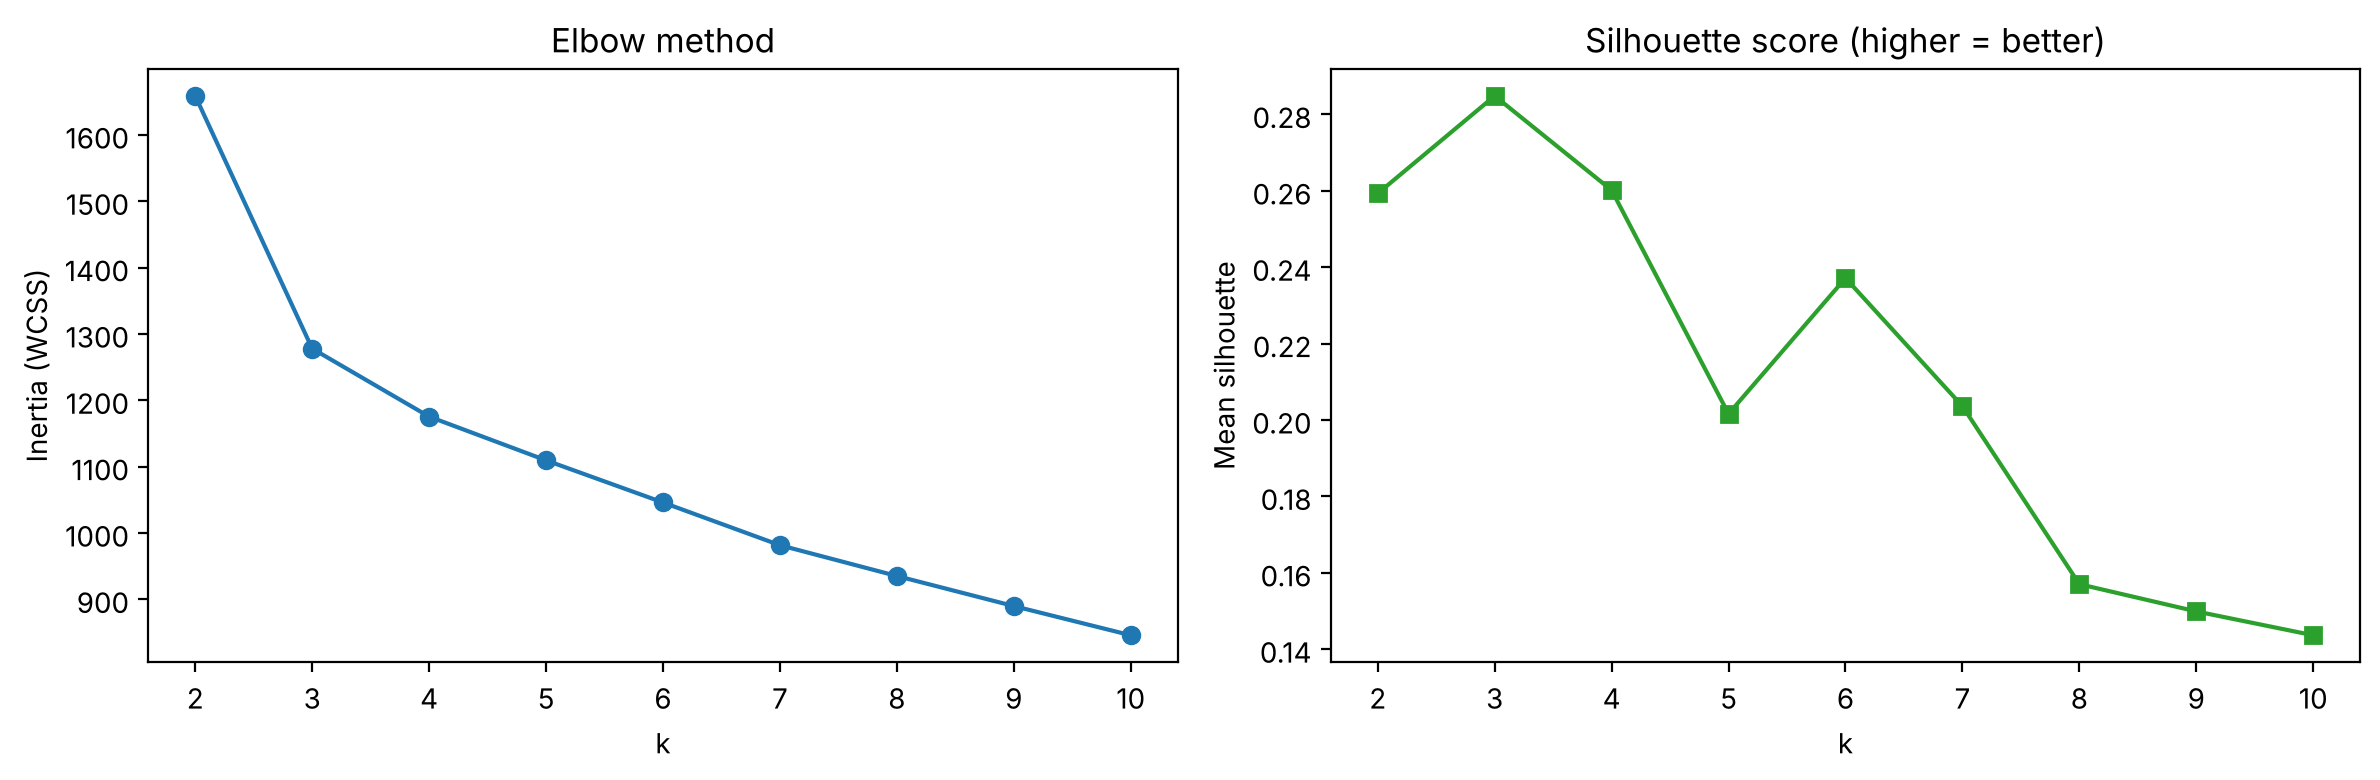

k with highest silhouette: 3


In [6]:
rows = []
for k in range(2, 11):
    km = KMeans(n_clusters=k, n_init=10, random_state=42).fit(X)
    rows.append({"k": k, "inertia": km.inertia_, "silhouette": silhouette_score(X, km.labels_),
                 "davies_bouldin": davies_bouldin_score(X, km.labels_), "calinski_harabasz": calinski_harabasz_score(X, km.labels_)})
sel = pd.DataFrame(rows).set_index("k")
display(sel.round(3))

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].plot(sel.index, sel["inertia"], "o-"); ax[0].set(xlabel="k", ylabel="Inertia (WCSS)", title="Elbow method")
ax[1].plot(sel.index, sel["silhouette"], "s-", color="tab:green"); ax[1].set(xlabel="k", ylabel="Mean silhouette", title="Silhouette score (higher = better)")
plt.tight_layout(); plt.show()
print("k with highest silhouette:", int(sel["silhouette"].idxmax()))

## Step 6 — Final model (k = 3) and evaluation

In [7]:
kmeans = KMeans(n_clusters=3, n_init=10, random_state=42).fit(X)
labels = kmeans.labels_
print("Iterations until convergence:", kmeans.n_iter_)
print("Cluster sizes:", np.bincount(labels))
print("Inertia: %.3f" % kmeans.inertia_)
print("Silhouette: %.4f | Davies–Bouldin: %.4f (lower is better) | Calinski–Harabasz: %.1f (higher is better)"
      % (silhouette_score(X, labels), davies_bouldin_score(X, labels), calinski_harabasz_score(X, labels)))

print("\nExternal check against the real cultivars (labels were NOT used for training):")
print("Adjusted Rand Index = %.4f | Normalised Mutual Information = %.4f" %
      (adjusted_rand_score(y_true, labels), normalized_mutual_info_score(y_true, labels)))
display(pd.crosstab(pd.Series(y_true, name="true cultivar"), pd.Series(labels, name="cluster")))

Iterations until convergence: 7
Cluster sizes: [65 51 62]
Inertia: 1277.928
Silhouette: 0.2849 | Davies–Bouldin: 1.3892 (lower is better) | Calinski–Harabasz: 70.9 (higher is better)

External check against the real cultivars (labels were NOT used for training):


Adjusted Rand Index = 0.8975 | Normalised Mutual Information = 0.8759


cluster,0,1,2
true cultivar,,,
0,0,0,59
1,65,3,3
2,0,48,0


### Silhouette plot
Each bar is one sample; wide, long, uniform bars above the dashed average line mean a compact, well-separated cluster.

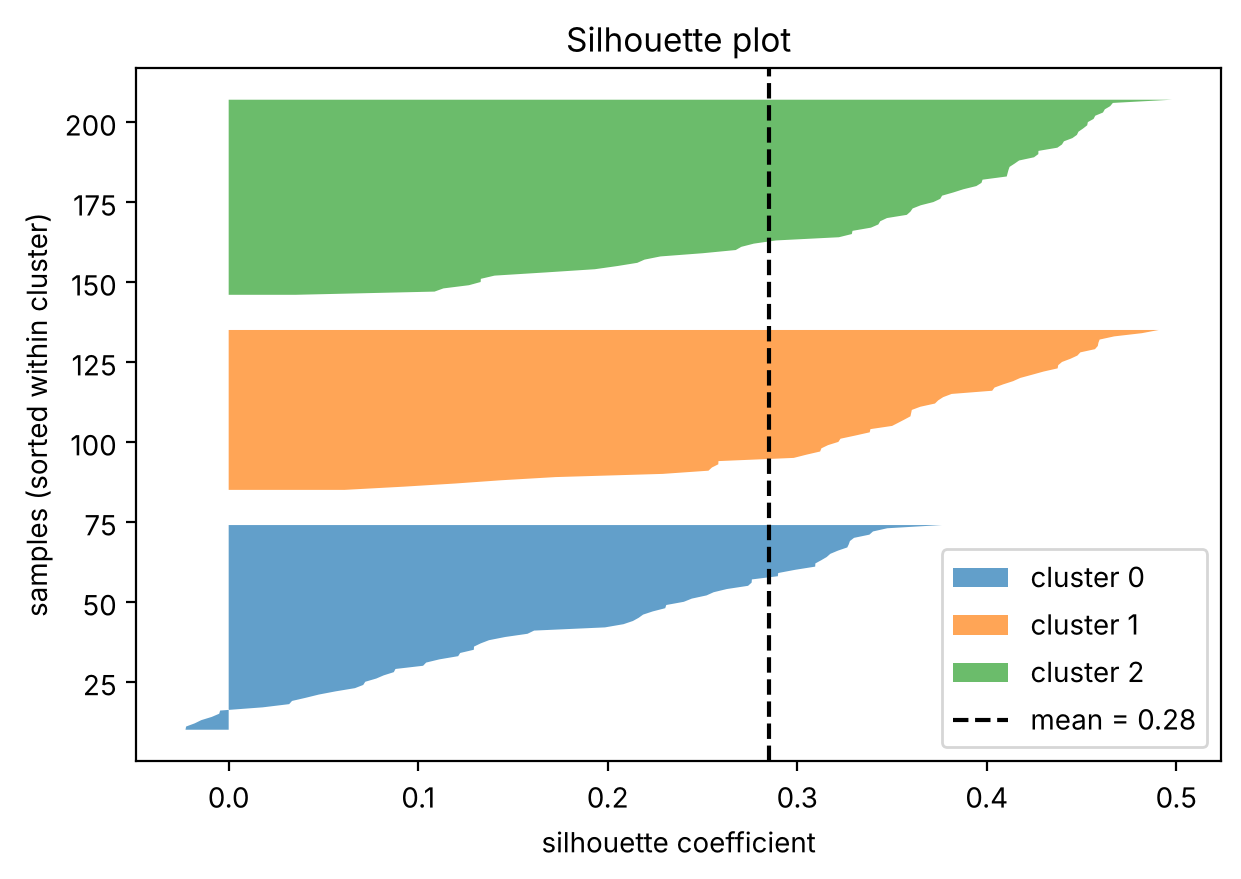

In [8]:
sil = silhouette_samples(X, labels)
fig, ax = plt.subplots(figsize=(7, 4.5))
y_lower = 10
for c in range(3):
    vals = np.sort(sil[labels == c])
    ax.fill_betweenx(np.arange(y_lower, y_lower + len(vals)), 0, vals, alpha=0.7, label=f"cluster {c}")
    y_lower += len(vals) + 10
ax.axvline(sil.mean(), color="k", ls="--", label=f"mean = {sil.mean():.2f}")
ax.set(xlabel="silhouette coefficient", ylabel="samples (sorted within cluster)", title="Silhouette plot"); ax.legend(); plt.show()

## Step 7 — Visualise the clusters (PCA to 2-D)

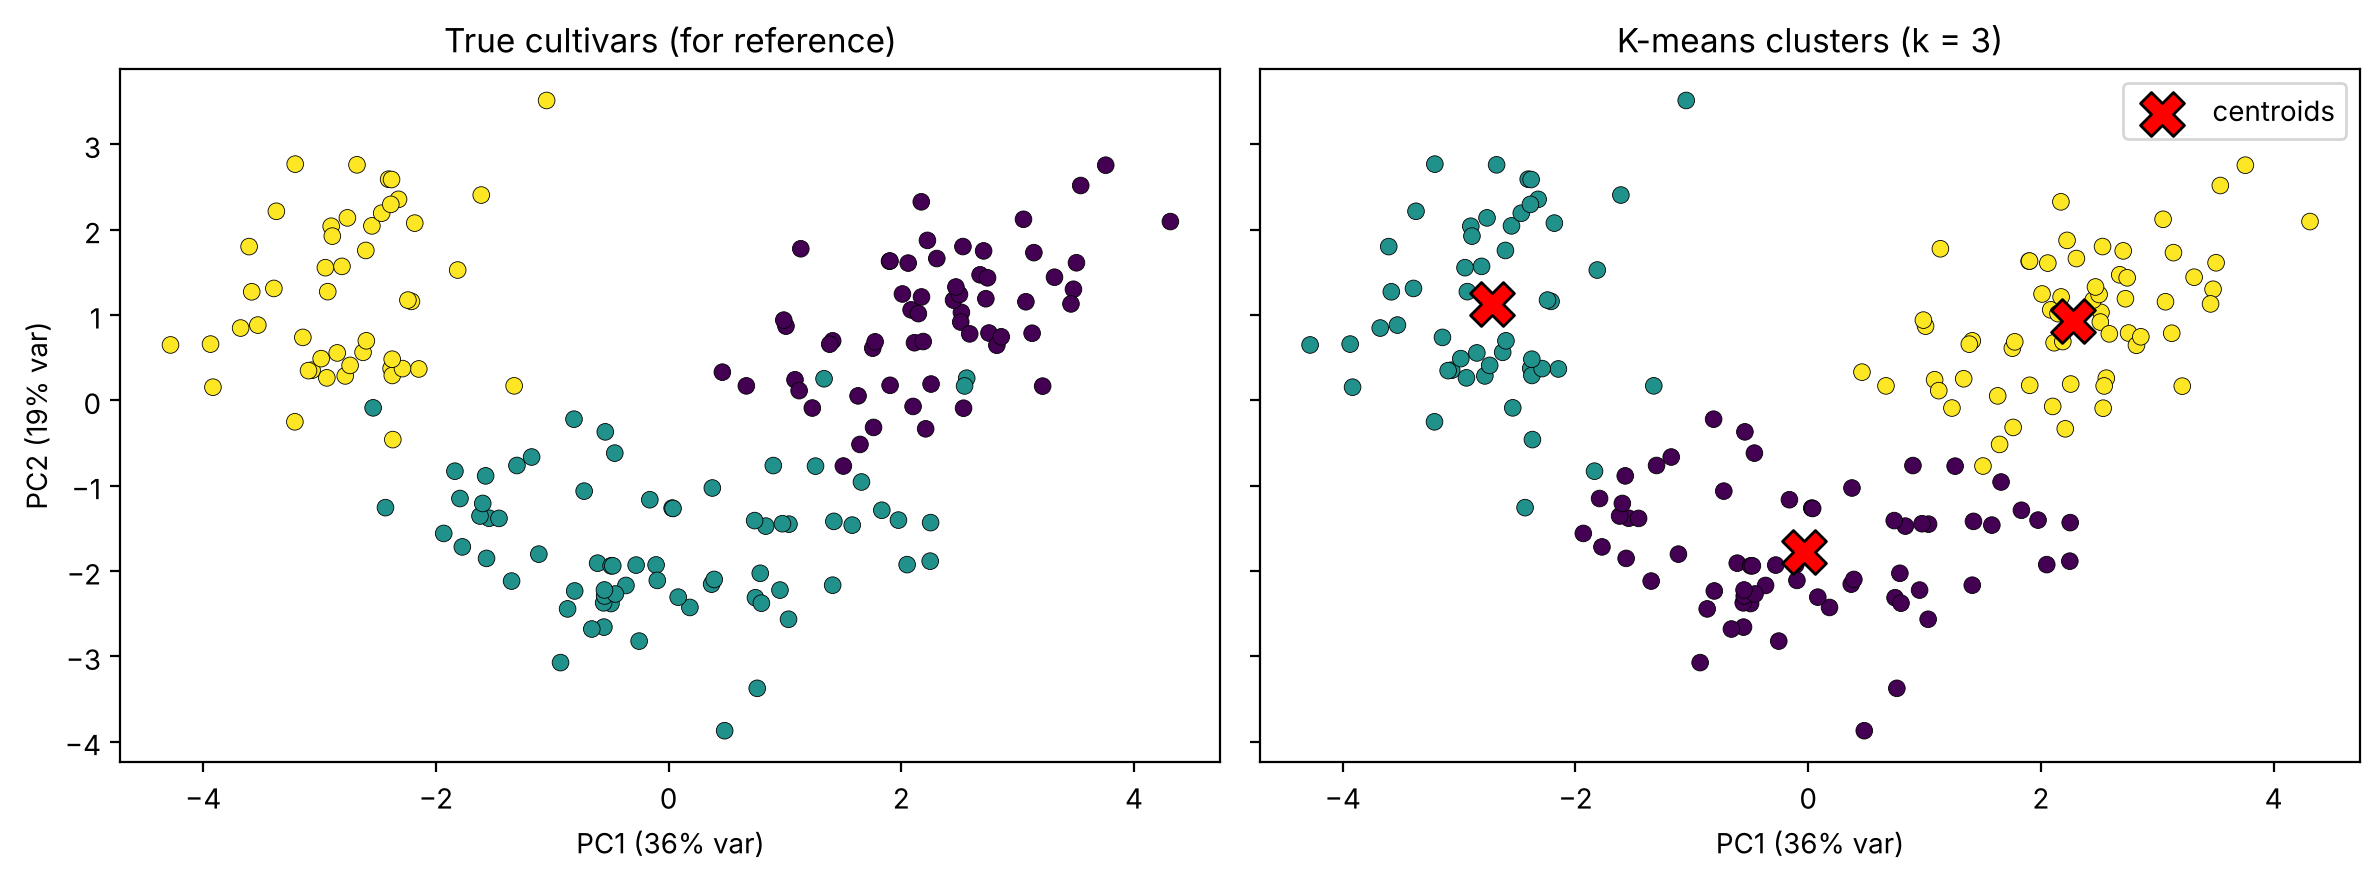

In [9]:
pca = PCA(n_components=2).fit(X)
P = pca.transform(X)
C = pca.transform(kmeans.cluster_centers_)
fig, ax = plt.subplots(1, 2, figsize=(12, 4.5), sharex=True, sharey=True)
ax[0].scatter(P[:, 0], P[:, 1], c=y_true, cmap="viridis", edgecolor="k", linewidth=0.3); ax[0].set_title("True cultivars (for reference)")
ax[1].scatter(P[:, 0], P[:, 1], c=labels, cmap="viridis", edgecolor="k", linewidth=0.3)
ax[1].scatter(C[:, 0], C[:, 1], c="red", marker="X", s=250, edgecolor="k", label="centroids"); ax[1].legend(); ax[1].set_title("K-means clusters (k = 3)")
for a in ax: a.set_xlabel("PC1 (%.0f%% var)" % (100 * pca.explained_variance_ratio_[0])); 
ax[0].set_ylabel("PC2 (%.0f%% var)" % (100 * pca.explained_variance_ratio_[1]))
plt.tight_layout(); plt.show()

### What characterises each cluster?
Cluster centroids converted back to the original units.

In [10]:
scaler = StandardScaler().fit(X_df)
profile = pd.DataFrame(scaler.inverse_transform(kmeans.cluster_centers_), columns=X_df.columns).T
profile.columns = [f"cluster {c}" for c in range(3)]
display(profile.round(2))

,cluster 0,cluster 1,cluster 2
alcohol,12.25,13.13,13.68
malic_acid,1.90,3.31,2.00
ash,2.23,2.42,2.47
alcalinity_of_ash,20.06,21.24,17.46
magnesium,92.74,98.67,107.97
total_phenols,2.25,1.68,2.85
flavanoids,2.05,0.82,3.00
nonflavanoid_phenols,0.36,0.45,0.29
proanthocyanins,1.62,1.15,1.92
color_intensity,2.97,7.23,5.45


## Step 8 — Assigning unseen data (train / test idea)
Fit the scaler and K-means on 80 % of the wines, then use `predict()` on the held-out 20 %. `predict` simply computes the
distance to each learned centroid and returns the nearest one – no re-clustering happens.

In [11]:
Xtr_df, Xte_df, ytr, yte = train_test_split(X_df, y_true, test_size=0.2, stratify=y_true, random_state=42)
sc = StandardScaler().fit(Xtr_df)
Xtr, Xte = sc.transform(Xtr_df), sc.transform(Xte_df)
km_tr = KMeans(n_clusters=3, n_init=10, random_state=42).fit(Xtr)
pred_te = km_tr.predict(Xte)

d0 = np.linalg.norm(km_tr.cluster_centers_ - Xte[0], axis=1)
print("Test sample 0: distances to the 3 centroids =", d0.round(3), "→ nearest = cluster", d0.argmin(), "| km.predict =", pred_te[0])
print("Train silhouette: %.4f | Test silhouette: %.4f" % (silhouette_score(Xtr, km_tr.labels_), silhouette_score(Xte, pred_te)))
print("Train ARI: %.4f | Test ARI: %.4f" % (adjusted_rand_score(ytr, km_tr.labels_), adjusted_rand_score(yte, pred_te)))

Test sample 0: distances to the 3 centroids = [2.182 6.594 5.126] → nearest = cluster 0 | km.predict = 0
Train silhouette: 0.2875 | Test silhouette: 0.2721
Train ARI: 0.8937 | Test ARI: 0.9088


## Step 9 — Stability across random initialisations
K-means depends on the random start. Run 20 single-start fits; a robust solution gives (nearly) the same inertia each time.

In [12]:
inertias = [KMeans(n_clusters=3, init="random", n_init=1, random_state=s).fit(X).inertia_ for s in range(20)]
print("Inertia over 20 single random starts → min %.2f | max %.2f | distinct values: %d" %
      (min(inertias), max(inertias), len(set(np.round(inertias, 3)))))

Inertia over 20 single random starts → min 1277.93 | max 1595.81 | distinct values: 6


### Conclusion
* Lloyd's algorithm (assign → update → repeat) converges in a handful of iterations; the manual implementation matches scikit-learn exactly when given the same starting centroids.
* Both the elbow plot and the silhouette score point to a small k (≈ 3), which agrees with the three true wine cultivars (high ARI / NMI) even though the labels were never used.
* Scaling is crucial; `n_init > 1` protects against poor local minima.
* K-means assumes compact, roughly spherical clusters of similar size – for other shapes use hierarchical or density-based clustering.